# 13. Benchmark: resultados e inferencia estadística

En este capítulo comparamos los diez modelos profundos y los dos baselines no profundos sobre las 361 imágenes del conjunto de prueba, con 8 semillas por modelo. Presentamos la tabla principal, las pruebas globales y por pares, sus supuestos, las pruebas por imagen, la potencia del experimento y el análisis de eficiencia. La regla de decisión es la del capítulo 11: una diferencia es relevante si es significativa con la t pareada corregida por Holm sobre los 45 pares y su magnitud es al menos $\delta = 0.02$.

In [1]:
import sys, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
from IPython.display import display, Markdown
import figuras as FG
from comun import MODELS, E2_MODELS, MACHINE
FG.setup()
pd.set_option("display.precision", 4)
SUM = E2 / "results" / "summary"
COMP = E2 / "results" / "complementario"
mc = pd.read_csv(SUM / "metricas_por_corrida.csv")
w = pd.read_csv(SUM / "f1_macro_por_semilla.csv").set_index("seed")[MODELS]
bl = pd.read_csv(COMP / "baselines.csv")
glob = json.load(open(COMP / "estadistica_complementaria.json"))
eg = json.load(open(SUM / "estadistica_global.json"))

## 13.1 Tabla principal del benchmark (plantilla A.2)

Para cada modelo reportamos:

- **F1 macro:** media ± DE sobre 8 semillas, con IC 95 % bootstrap sobre las semillas (10 000 remuestreos).
- **Calibración:** ECE de 15 bins.
- **Robustez:** índice de área bajo la curva de degradación con ruido gaussiano ($\sigma \in \{0, 0.05, 0.10\}$), normalizado por el F1 sin perturbar; vale 1 si el modelo no se degrada (sección 15.1).
- **Costo:** parámetros, GMAC por imagen y latencia por imagen en lote de 32, en la GPU indicada.
- **Rango promedio:** rango de Friedman, donde 1 es el mejor.

Los baselines trivial y clásico se describen en la sección 13.2.

In [2]:
rng = np.random.default_rng(0)
ri = pd.read_csv(COMP / "robustez_indice.csv").groupby("model").ir_ruido.mean()
g = mc.groupby("model")
rows = []
for m in MODELS:
    x = w[m].to_numpy()
    bs = x[rng.integers(0, 8, (10000, 8))].mean(1)
    rows.append({"modelo": m, "origen": "E1" if m in ("CNN", "MobileNetV2", "ResNet-18") else "E2",
                 "F1 macro": f"{x.mean():.3f} ± {x.std(ddof=1):.3f}",
                 "IC 95 % bootstrap": f"[{np.percentile(bs, 2.5):.3f}, {np.percentile(bs, 97.5):.3f}]",
                 "accuracy": g.accuracy.mean()[m], "bal. acc.": g.balanced_accuracy.mean()[m], "MCC": g.mcc.mean()[m],
                 "AUC-ROC": g.auc_roc_macro.mean()[m], "ECE": g.ece.mean()[m], "índice robustez": ri[m],
                 "parámetros (M)": g.params.first()[m] / 1e6, "GMAC": g.gmacs.first()[m],
                 "ms/imagen": g.ms_per_image.mean()[m], "GPU": MACHINE[m],
                 "rango Friedman": glob["rangos_medios"][m]})
for name, sub in bl.groupby("model"):
    rows.append({"modelo": name, "origen": "baseline", "F1 macro": f"{sub.f1_macro.mean():.3f} ± {sub.f1_macro.std(ddof=1) if len(sub) > 1 else 0:.3f}",
                 "IC 95 % bootstrap": "—", "accuracy": sub.accuracy.mean(), "bal. acc.": sub.balanced_accuracy.mean(),
                 "MCC": sub.mcc.mean()})
tabla = pd.DataFrame(rows).set_index("modelo").sort_values("rango Friedman", na_position="last")
display(tabla.round(3))

,origen,F1 macro,IC 95 % bootstrap,accuracy,bal. acc.,MCC,AUC-ROC,ECE,índice robustez,parámetros (M),GMAC,ms/imagen,GPU,rango Friedman
modelo,,,,,,,,,,,,,,
RWCNet,E2,0.945 ± 0.010,"[0.938, 0.951]",0.952,0.951,0.941,0.997,0.027,0.694,25.604,4.589,2.283,RTX 4060,1.500
ViT-B16,E2,0.938 ± 0.014,"[0.930, 0.947]",0.944,0.935,0.931,0.995,0.042,0.950,85.803,17.563,0.459,A100,2.000
GFN,E2,0.921 ± 0.015,"[0.912, 0.931]",0.935,0.919,0.921,0.992,0.051,0.834,113.671,5.675,0.967,A100,3.250
Celik-HC,E2,0.914 ± 0.013,"[0.905, 0.923]",0.926,0.912,0.910,0.986,0.056,0.424,28.424,3.223,1.120,A100,3.750
ResMsCapsule,E2,0.899 ± 0.015,"[0.889, 0.909]",0.911,0.901,0.892,0.983,0.193,0.529,4.217,1.420,0.405,RTX 4060,4.750
MbXception,E2,0.861 ± 0.014,"[0.852, 0.869]",0.874,0.863,0.847,0.981,0.057,0.409,28.393,6.195,1.418,RTX 4060,6.500
ResNet-18,E1,0.863 ± 0.022,"[0.848, 0.876]",0.871,0.861,0.842,0.979,0.051,0.512,11.180,1.814,0.327,RTX 4060,6.500
CNN,E1,0.826 ± 0.022,"[0.811, 0.839]",0.849,0.846,0.817,0.973,0.060,0.402,1.175,2.587,0.677,RTX 4060,8.500
FocusRCNet,E2,0.811 ± 0.015,"[0.802, 0.822]",0.832,0.819,0.795,0.968,0.132,0.362,0.521,0.127,0.368,RTX 4060,9.125


La tabla completa de métricas secundarias por modelo (F1 ponderado, precisión y recall macro, AUC-PR, NLL, Brier, tiempos) está en `entregable2/results/summary/tabla_benchmark.csv`, y las métricas de cada corrida en `metricas_por_corrida.csv`. Los modelos del capítulo 4 no guardaron NLL ni Brier.

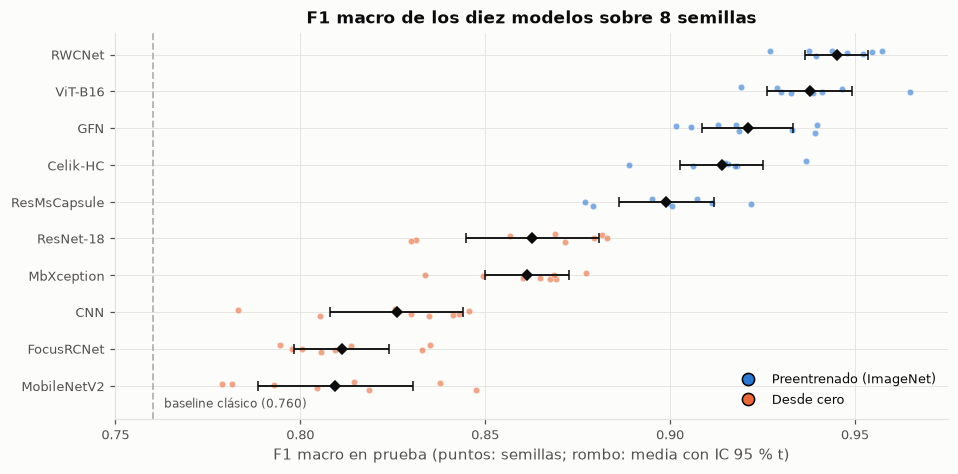

In [3]:
fig, ax = plt.subplots(figsize=(8.8, 4.4))
orden = w.mean().sort_values().index
for i, m in enumerate(orden):
    x = w[m].to_numpy()
    ax.scatter(x, np.full(8, i) + np.random.default_rng(i).uniform(-0.12, 0.12, 8), s=18, color=FG.color_regimen(m), alpha=0.6,
               edgecolor=FG.SURFACE, lw=0.5, zorder=3)
    h = st.t.ppf(0.975, 7) * x.std(ddof=1) / np.sqrt(8)
    ax.errorbar(x.mean(), i, xerr=h, fmt="D", color=FG.INK, ms=5, capsize=3, lw=1.2, zorder=4)
for name, sub in bl.groupby("model"):
    if "Hist" in name:
        ax.axvline(sub.f1_macro.mean(), color=FG.NEUTRAL, lw=1.2, ls="--")
        ax.text(sub.f1_macro.mean() + 0.003, -0.6, "baseline clásico (0.760)", fontsize=8, color=FG.INK2)
ax.set_yticks(range(len(orden)), orden); ax.set_ylim(-0.9, len(orden) - 0.4)
ax.set_xlabel("F1 macro en prueba (puntos: semillas; rombo: media con IC 95 % t)")
ax.set_title("F1 macro de los diez modelos sobre 8 semillas")
FG.leyenda_regimen(ax, loc="lower right"); plt.tight_layout(); plt.show()

## 13.2 Baselines no profundos

- **Baseline trivial:** predice siempre `paper`, la clase mayoritaria del entrenamiento.
- **Baseline clásico:** *gradient boosting* (`HistGradientBoostingClassifier`) sobre 390 descriptores manuales por imagen:
  - histogramas HSV;
  - media y desviación estándar RGB;
  - histogramas de orientación del gradiente en una malla de 4×4 (tipo HOG);
  - una miniatura en escala de grises.

El baseline clásico recibió el mismo presupuesto de ajuste que los modelos profundos: 8 configuraciones (tasa {0.1, 0.05} × hojas {15, 31} × regularización L2 {0, 1}), semilla 100, selección por F1 macro de validación y 8 semillas finales (`entregable2/analisis/baselines.py`). Sin submuestreo ni parada temprana, el algoritmo es determinista: sus 8 semillas dan el mismo resultado y su varianza entre semillas es nula.

In [4]:
bh = pd.read_csv(COMP / "baseline_clasico_busqueda.csv")
display(bh.round(4))
triv = bl[bl.model.str.startswith("Trivial")].iloc[0]
clas = bl[bl.model.str.startswith("Hist")].f1_macro.mean()
filas = []
for m in MODELS:
    x = w[m].to_numpy()
    for nombre, ref in [("clásico", clas), ("trivial", triv.f1_macro)]:
        t = st.ttest_1samp(x - ref, 0, alternative="greater")
        filas.append({"modelo": m, "frente a": nombre, "diferencia": x.mean() - ref, "p unilateral": t.pvalue})
cmp_ = pd.DataFrame(filas)
from statsmodels.stats.multitest import multipletests
cmp_["p Holm (20)"] = multipletests(cmp_["p unilateral"], method="holm")[1]
cmp_["> δ y significativa"] = (cmp_.diferencia >= 0.02) & (cmp_["p Holm (20)"] < 0.05)
display(cmp_.pivot(index="modelo", columns="frente a", values=["diferencia", "p Holm (20)"]).loc[MODELS].round(5))
print("Todos los modelos superan a ambos baselines con diferencia ≥ δ y p Holm < 0.05:", bool(cmp_["> δ y significativa"].all()))

,trial,learning_rate,max_leaf_nodes,l2_regularization,val_f1_macro
0,0,0.10,15,0.0,0.7873
1,1,0.10,15,1.0,0.7908
2,2,0.10,31,0.0,0.7930
3,3,0.10,31,1.0,0.7732
4,4,0.05,15,0.0,0.7964
5,5,0.05,15,1.0,0.7715
6,6,0.05,31,0.0,0.7788
7,7,0.05,31,1.0,0.7843


diferencia         p Holm (20)        
frente a        clásico trivial     clásico trivial
modelo                                             
Celik-HC         0.1538  0.8504  0.0000e+00     0.0
MbXception       0.1012  0.7978  0.0000e+00     0.0
ViT-B16          0.1776  0.8743  0.0000e+00     0.0
GFN              0.1609  0.8575  0.0000e+00     0.0
FocusRCNet       0.0510  0.7476  5.0000e-05     0.0
ResMsCapsule     0.1388  0.8355  0.0000e+00     0.0
RWCNet           0.1849  0.8815  0.0000e+00     0.0
CNN              0.0659  0.7625  5.0000e-05     0.0
MobileNetV2      0.0493  0.7460  4.2000e-04     0.0
ResNet-18        0.1027  0.7993  1.0000e-05     0.0

Todos los modelos superan a ambos baselines con diferencia ≥ δ y p Holm < 0.05: True


Los diez modelos profundos superan a los dos baselines. El peor de ellos (MobileNetV2, 0.809) aventaja al baseline clásico en 0.049, y el mejor (RWCNet) en 0.185. El baseline clásico confirma que la tarea no se resuelve con color y textura global, a pesar del atajo de fondo del capítulo 2. Su F1 de 0.760 es la ganancia mínima que debe justificar cualquier modelo profundo, y la diferencia entre el baseline clásico y el mejor modelo cuantifica el aporte real del Deep Learning en este problema.

## 13.3 Prueba global y supuestos

**Supuestos.**

- **Independencia:** cada semilla es una corrida independiente; dentro de una semilla, los diez modelos comparten la partición y el orden de los datos, por lo que las semillas actúan como bloques.
- **Normalidad:** se evalúa con Shapiro-Wilk sobre el F1 de cada modelo y sobre las diferencias pareadas.
- **Homocedasticidad:** se evalúa con Levene (centrado en la mediana).

Como la potencia de estas pruebas es baja con 8 semillas, reportamos en paralelo una prueba paramétrica (ANOVA de medidas repetidas con corrección de Greenhouse-Geisser) y una no paramétrica (Friedman con $p$ por permutación y corrección de Iman-Davenport).

In [5]:
sh = pd.Series(glob["shapiro_p_por_modelo"]).rename("Shapiro-Wilk p")
display(sh.to_frame().T.round(3))
pp = pd.read_csv(SUM / "pruebas_pares.csv")
print(f"Levene (mediana): W = {glob['levene_W']:.3f}, p = {glob['levene_p']:.3f}")
print(f"Shapiro-Wilk sobre las 45 diferencias pareadas: {int((pp.shapiro_p_dif < 0.05).sum())} con p < 0.05 "
      f"(se esperan {0.05 * 45:.1f} por azar)")
gl = pd.DataFrame([
    ("Friedman (permutación, 100 000)", f"Q = {eg['friedman']['Q']:.2f}", f"p < {1/100001:.0e}", f"W de Kendall = {eg['friedman']['W_kendall']:.2f}"),
    ("Friedman con Iman-Davenport", f"F({glob['iman_davenport_gl'][0]}, {glob['iman_davenport_gl'][1]}) = {glob['iman_davenport_F']:.1f}",
     f"p = {max(glob['iman_davenport_p'], 1e-16):.1e}", ""),
    ("ANOVA de medidas repetidas (Greenhouse-Geisser)", f"F = {glob['anova_rm_F']:.1f}, ε = {glob['gg_epsilon']:.2f}",
     f"p = {glob['anova_rm_p_gg']:.1e}", f"η² parcial = {glob['eta2_parcial']:.2f}"),
    ("ANOVA de un factor sobre las 80 corridas", f"F = {eg['descomposicion_varianza']['F']:.1f}", f"p = {eg['descomposicion_varianza']['p']:.1e}",
     f"η² = {eg['descomposicion_varianza']['eta2']:.2f}; ICC(1) = {eg['descomposicion_varianza']['icc1']:.2f}"),
], columns=["prueba", "estadístico", "p", "tamaño de efecto"])
display(gl)

,Celik-HC,MbXception,ViT-B16,GFN,FocusRCNet,ResMsCapsule,RWCNet,CNN,MobileNetV2,ResNet-18
Shapiro-Wilk p,0.295,0.211,0.658,0.376,0.203,0.732,0.817,0.098,0.697,0.061


Levene (mediana): W = 0.965, p = 0.477
Shapiro-Wilk sobre las 45 diferencias pareadas: 3 con p < 0.05 (se esperan 2.2 por azar)


,prueba,estadístico,p,tamaño de efecto
0,"Friedman (permutación, 100 000)",Q = 64.77,p < 1e-05,W de Kendall = 0.90
1,Friedman con Iman-Davenport,"F(9, 63) = 62.7",p = 1.0e-16,
2,ANOVA de medidas repetidas (Greenhouse-Geisser),"F = 76.1, ε = 0.44",p = 2.1e-14,η² parcial = 0.92
3,ANOVA de un factor sobre las 80 corridas,F = 73.6,p = 4.0e-32,η² = 0.90; ICC(1) = 0.90


**RQ1.** Los diez modelos no tienen el mismo desempeño. Friedman rechaza la hipótesis nula ($p < 10^{-5}$) con un acuerdo muy alto entre semillas ($W = 0.90$), y la prueba paramétrica coincide. El modelo explica el 90 % de la varianza del F1 entre corridas y la semilla el 10 % restante, frente al 52 % del capítulo 5: al ampliar el rango de arquitecturas, la semilla pierde peso relativo. Ninguna prueba de normalidad por modelo rechaza al 5 %, y Levene no indica varianzas distintas, lo que respalda la t pareada como prueba de decisión.

## 13.4 Diagrama de diferencia crítica

El diagrama ordena los modelos por su rango medio (1 = mejor) y une con una barra los grupos cuya diferencia de rango es menor que la diferencia crítica de Nemenyi,

$$\text{CD} = q_\alpha \sqrt{\frac{k(k+1)}{6N}} = 3.164\sqrt{\frac{10 \cdot 11}{6 \cdot 8}} = 4.79.$$

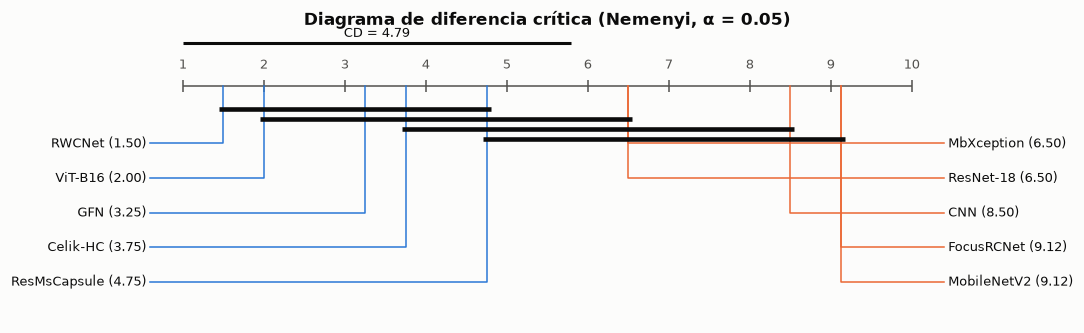

In [6]:
ranks = pd.Series(glob["rangos_medios"]).sort_values()
cd = glob["nemenyi_CD"]
fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.set_xlim(0.5, 10.5); ax.set_ylim(0, 1); ax.axis("off")
ax.hlines(0.82, 1, 10, color=FG.INK2, lw=1)
for k in range(1, 11):
    ax.vlines(k, 0.80, 0.84, color=FG.INK2, lw=1); ax.text(k, 0.88, str(k), ha="center", fontsize=8.5, color=FG.INK2)
ax.hlines(0.97, 1, 1 + cd, color=FG.INK, lw=2); ax.text(1 + cd / 2, 0.99, f"CD = {cd:.2f}", ha="center", fontsize=8.5)
items = list(ranks.items())
for i, (m, r) in enumerate(items):
    left = i < 5
    yy = 0.62 - (i if left else i - 5) * 0.12
    xt = 0.6 if left else 10.4
    ax.plot([r, r, xt], [0.82, yy, yy], color=FG.color_regimen(m), lw=1)
    ax.text(xt + (-0.05 if left else 0.05), yy, f"{m} ({r:.2f})", ha="right" if left else "left", va="center", fontsize=8.5)
# grupos no distinguibles: intervalos maximales con amplitud < CD
vals = ranks.values; grupos = []
for i in range(len(vals)):
    j = max(k for k in range(len(vals)) if vals[k] - vals[i] < cd)
    if j > i and not any(a <= i and j <= b for a, b in grupos):
        grupos.append((i, j))
for n, (i, j) in enumerate(grupos):
    y = 0.74 - n * 0.035
    ax.hlines(y, vals[i] - 0.05, vals[j] + 0.05, color=FG.INK, lw=3)
ax.set_title("Diagrama de diferencia crítica (Nemenyi, α = 0.05)")
plt.show()

Nemenyi es conservadora con 10 modelos y 8 bloques: solo separa pares con diferencias de rango mayores que 4.79. Por eso los grupos se solapan. RWCNet, ViT-B16, GFN, Celik-HC y ResMsCapsule no se distinguen entre sí por rangos, pero sí del grupo inferior (FocusRCNet, MobileNetV2 y CNN). Las comparaciones por pares de la sección 13.5 usan las diferencias de F1 y no solo los rangos, y tienen más potencia.

## 13.5 Contrastes confirmatorios (plantilla A.3)

**RQ2: cada modelo publicado frente al modelo de referencia (ResNet-18).** Los 7 contrastes forman parte de la familia preregistrada de 45 pares, y el $p$ se ajusta por Holm sobre los 45. Como análisis de sensibilidad mostramos también el ajuste dentro de la subfamilia de 7. Cada contraste se evalúa con tres pruebas distintas:

1. t pareada, con normalidad verificada (prueba paramétrica pareada);
2. Wilcoxon (no paramétrica);
3. Friedman con post hoc de Conover-Holm (procedimiento global con control de comparaciones múltiples, sección 13.6).

In [7]:
fam = pd.read_csv(COMP / "familia_vs_resnet18.csv")
con = pd.read_csv(SUM / "posthoc_conover_holm.csv").set_index("model")
fam["Conover-Holm p"] = [con.loc[m, "ResNet-18"] for m in fam.modelo]
fam["IC 95 % (t)"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(fam.ic_t_lo, fam.ic_t_hi)]
fam["IC 95 % (bootstrap)"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(fam.ic_boot_lo, fam.ic_boot_hi)]
fam["≥ 0.036 (umbral del cap. 7)"] = fam.dif >= 0.036
display(fam[["modelo", "dif", "IC 95 % (t)", "IC 95 % (bootstrap)", "d_z", "shapiro_p", "p_t", "p_t_holm_45", "p_t_holm_7",
             "p_wilcoxon", "Conover-Holm p", "≥ 0.036 (umbral del cap. 7)", "decision"]]
        .set_index("modelo").round(4))

,dif,IC 95 % (t),IC 95 % (bootstrap),d_z,shapiro_p,p_t,p_t_holm_45,p_t_holm_7,p_wilcoxon,Conover-Holm p,≥ 0.036 (umbral del cap. 7),decision
modelo,,,,,,,,,,,,
Celik-HC,0.0511,"[0.030, 0.073]","[0.034, 0.068]",1.9815,0.6705,0.0008,0.0154,0.0032,0.0078,0.0000,True,superior: significativa y relevante
MbXception,-0.0015,"[-0.021, 0.018]","[-0.017, 0.014]",-0.0629,0.9598,0.8637,1.0000,0.8637,0.8438,1.0000,False,no concluyente
ViT-B16,0.0750,"[0.051, 0.098]","[0.057, 0.094]",2.6688,0.3975,0.0001,0.0037,0.0008,0.0078,0.0000,True,superior: significativa y relevante
GFN,0.0582,"[0.032, 0.084]","[0.039, 0.079]",1.8673,0.3680,0.0011,0.0205,0.0034,0.0078,0.0000,True,superior: significativa y relevante
FocusRCNet,-0.0516,"[-0.072, -0.032]","[-0.068, -0.037]",-2.1678,0.5620,0.0005,0.0100,0.0024,0.0078,0.0001,False,inferior: significativa y relevante
ResMsCapsule,0.0362,"[0.011, 0.061]","[0.018, 0.055]",1.2179,0.6026,0.0108,0.1292,0.0215,0.0156,0.0147,True,no concluyente
RWCNet,0.0822,"[0.069, 0.095]","[0.072, 0.092]",5.2538,0.9892,0.0000,0.0001,0.0000,0.0078,0.0000,True,superior: significativa y relevante


**Respuesta a RQ2.** Cuatro modelos publicados superan al modelo de referencia del capítulo 7 por más del umbral de 0.036, con significancia tras Holm y con las tres pruebas en el mismo sentido:

| Modelo | Diferencia de F1 frente a ResNet-18 | $d_z$ | $p$ Holm (t) |
|---|---|---|---|
| RWCNet | +0.082 | 5.3 | < 0.001 |
| ViT-B16 | +0.075 | 2.7 | 0.004 |
| GFN | +0.058 | 1.9 | 0.021 |
| Celik-HC | +0.051 | 2.0 | 0.015 |

Los cuatro son preentrenados.

Los demás resultados son:

- **ResMsCapsule** supera a ResNet-18 en 0.036, pero no es significativo con Holm sobre los 45 pares ($p = 0.13$). Dentro de la subfamilia de 7 sí lo es ($p = 0.02$), por lo que el resultado depende de la familia elegida; según la regla preregistrada es no concluyente.
- **MbXception**, entrenado desde cero, no difiere de ResNet-18 (−0.002, $p = 1.0$). La diferencia no demuestra equivalencia.
- **FocusRCNet** es inferior a ResNet-18 (−0.052, $p$ Holm = 0.010).

Wilcoxon da $p = 0.0078$ en todos los contrastes con las 8 diferencias del mismo signo, el mínimo posible con $n = 8$. Tras Holm no alcanza significancia por la razón explicada en la sección 11.2.

## 13.6 Comparaciones entre los mejores modelos, equivalencia y sensibilidad

In [8]:
eq = pd.read_csv(COMP / "equivalencia_tost_rope.csv")
top = ["RWCNet", "ViT-B16", "GFN", "Celik-HC", "ResMsCapsule"]
e = eq[eq.A.isin(top) & eq.B.isin(top)].copy()
e = e.merge(pp[["A", "B", "p_t_holm"]], on=["A", "B"], how="left").merge(
    pp[["A", "B", "p_t_holm"]].rename(columns={"A": "B", "B": "A"}), on=["A", "B"], how="left", suffixes=("", "_r"))
e["p_t_holm"] = e.p_t_holm.fillna(e.p_t_holm_r)
e["Conover-Holm p"] = [con.loc[a, b] for a, b in zip(e.A, e.B)]
display(e[["A", "B", "dif_media", "ic90_lo", "ic90_hi", "p_t_holm", "Conover-Holm p", "p_tost", "p_bayes_A_peor", "p_bayes_rope",
           "p_bayes_A_mejor", "A12"]].sort_values("dif_media").round(3).reset_index(drop=True))

,A,B,dif_media,ic90_lo,ic90_hi,p_t_holm,Conover-Holm p,p_tost,p_bayes_A_peor,p_bayes_rope,p_bayes_A_mejor,A12
0,GFN,Celik-HC,0.007,-0.002,0.016,0.862,1.000,0.014,0.0,0.995,0.005,0.625
1,RWCNet,ViT-B16,0.007,-0.003,0.017,0.870,1.000,0.024,0.0,1.000,0.000,0.688
2,Celik-HC,ResMsCapsule,0.015,-0.000,0.030,0.755,0.389,0.278,0.0,0.882,0.118,0.781
3,ViT-B16,GFN,0.017,0.006,0.028,0.204,0.141,0.299,0.0,0.817,0.183,0.781
4,GFN,ResMsCapsule,0.022,0.008,0.036,0.187,0.043,0.606,0.0,0.616,0.384,0.859
5,ViT-B16,Celik-HC,0.024,0.010,0.038,0.151,0.015,0.693,0.0,0.334,0.666,0.938
6,RWCNet,GFN,0.024,0.009,0.039,0.184,0.015,0.686,0.0,0.480,0.520,0.906
7,RWCNet,Celik-HC,0.031,0.018,0.044,0.035,0.001,0.927,0.0,0.139,0.861,0.984
8,ViT-B16,ResMsCapsule,0.039,0.028,0.049,0.005,0.000,0.994,0.0,0.014,0.986,0.984
9,RWCNet,ResMsCapsule,0.046,0.034,0.058,0.005,0.000,0.997,0.0,0.003,0.997,1.000


Además de la diferencia y su $p$ ajustado, la tabla incluye tres medidas:

- **Equivalencia (TOST):** con margen $\pm\delta$; el IC 90 % de la diferencia debe quedar dentro de $(-0.02, 0.02)$.
- **Prueba bayesiana de rangos con signo** (Benavoli et al., 2017): probabilidad de que A sea peor, equivalente dentro de la región de equivalencia práctica (ROPE $= \pm\delta$) o mejor.
- **Probabilidad de superioridad** $A_{12}$ de Vargha y Delaney entre semillas.

Los resultados entre los mejores modelos son:

- **RWCNet frente a ViT-B16:** equivalentes en la práctica. La diferencia es de 0.007, TOST da $p = 0.024$ y la probabilidad bayesiana de la ROPE es 1.00. No hay un único modelo ganador: dos arquitecturas muy distintas, fusión de CNN y Transformer, alcanzan el mismo desempeño.
- **GFN frente a Celik-HC:** también equivalentes (diferencia de 0.007, TOST $p = 0.014$).
- **RWCNet frente a Celik-HC:** la única diferencia significativa y relevante entre los cinco mejores (0.031, $p$ Holm = 0.035).
- **ViT-B16 frente a Celik-HC y RWCNet frente a GFN:** la conclusión depende de la prueba. Conover-Holm las declara significativas y la t con Holm no; las clasificamos como no concluyentes.

In [9]:
sen = pd.read_csv(COMP / "sensibilidad_decision.csv")
res = pd.DataFrame({"prueba de decisión": ["t pareada + Holm (preregistrada)", "Wilcoxon + Holm", "IC bootstrap excluye 0",
                                           "Conover + Holm", "Nemenyi"],
                    "pares relevantes y significativos (de 45)": [int(sen[c].sum()) for c in
                                                                    ["t_holm", "wilcoxon_holm", "bootstrap_ic", "conover_holm", "nemenyi"]]})
display(res)
acuerdo = (sen.t_holm == sen.conover_holm).mean()
print(f"Acuerdo entre t-Holm y Conover-Holm en la decisión de los 45 pares: {100 * acuerdo:.0f} %")

,prueba de decisión,pares relevantes y significativos (de 45)
0,t pareada + Holm (preregistrada),32
1,Wilcoxon + Holm,0
2,IC bootstrap excluye 0,37
3,Conover + Holm,37
4,Nemenyi,13


Acuerdo entre t-Holm y Conover-Holm en la decisión de los 45 pares: 89 %


**Análisis de sensibilidad.** La conclusión principal (RQ2) se mantiene con la t pareada, el bootstrap y Conover. Wilcoxon con Holm no puede rechazar ningún par con 8 semillas, y Nemenyi es la prueba más conservadora. Las decisiones que cambian entre pruebas corresponden a diferencias cercanas a $\delta$, que reportamos como no concluyentes.

## 13.7 Pruebas por imagen: McNemar, Q de Cochran y DeLong

Las pruebas por imagen comparan modelos sobre el mismo conjunto de prueba dentro de cada semilla. Su unidad de análisis es la imagen, por lo que su conclusión se refiere a este conjunto de prueba y no a la variabilidad entre entrenamientos.

In [10]:
mn = pd.read_csv(SUM / "mcnemar_por_semilla.csv")
mn["sig"] = mn.p_holm_semilla < 0.05
pares = [("RWCNet", "ViT-B16"), ("RWCNet", "GFN"), ("RWCNet", "Celik-HC"), ("ViT-B16", "Celik-HC"), ("RWCNet", "ResNet-18"),
         ("ViT-B16", "ResNet-18"), ("Celik-HC", "ResNet-18"), ("GFN", "ResNet-18")]
filas = []
for a, b in pares:
    s = mn[((mn.A == a) & (mn.B == b)) | ((mn.A == b) & (mn.B == a))]
    filas.append({"par": f"{a} – {b}", "semillas con McNemar significativo (Holm por semilla)": f"{int(s.sig.sum())} de 8",
                  "discordantes medios (b + c)": (s.b + s.c).mean()})
display(pd.DataFrame(filas))
cq = pd.read_csv(COMP / "cochran_q.csv")
print(f"Q de Cochran (10 modelos, por semilla): Q entre {cq.Q_cochran.min():.0f} y {cq.Q_cochran.max():.0f}, gl = 9, p < 1e-10 en las 8 semillas")
dl = pd.read_csv(COMP / "delong_ovr.csv")
dls = dl.groupby(["A", "B", "clase"]).agg(dif_AUC=("dif", "mean"), semillas_sig=("p_holm", lambda x: int((x < 0.05).sum()))).reset_index()
display(dls.pivot(index=["A", "B"], columns="clase", values="semillas_sig"))

,par,semillas con McNemar significativo (Holm por semilla),discordantes medios (b + c)
0,RWCNet – ViT-B16,0 de 8,21.000
1,RWCNet – GFN,0 de 8,19.625
2,RWCNet – Celik-HC,1 de 8,23.375
3,ViT-B16 – Celik-HC,0 de 8,28.375
4,RWCNet – ResNet-18,8 de 8,42.875
5,ViT-B16 – ResNet-18,5 de 8,47.625
6,Celik-HC – ResNet-18,2 de 8,48.250
7,GFN – ResNet-18,4 de 8,45.000


Q de Cochran (10 modelos, por semilla): Q entre 90 y 156, gl = 9, p < 1e-10 en las 8 semillas


clase               cardboard  glass  metal  paper  plastic  trash
A        B                                                        
Celik-HC ResNet-18          0      0      1      2        0      0
RWCNet   Celik-HC           0      0      0      0        0      0
         GFN                0      0      0      0        0      0
         ResNet-18          0      2      1      7        3      0
         ViT-B16            0      0      0      0        0      0
ViT-B16  GFN                0      0      0      0        0      0

**McNemar.** Entre RWCNet y ViT-B16, ninguna semilla muestra una diferencia significativa en la tasa de error. Frente a ResNet-18, RWCNet difiere en las 8 semillas, ViT-B16 en 5, GFN en 4 y Celik-HC en 2: con 361 imágenes, McNemar solo detecta de forma consistente las diferencias mayores.

**Q de Cochran.** Rechaza en las 8 semillas que los diez modelos tengan la misma proporción de aciertos.

**DeLong.** Comparamos las AUC uno contra todos por clase. Elegimos este esquema porque la AUC macro es un promedio de AUC binarias con muestras de positivos distintas. La tabla cuenta en cuántas semillas la diferencia de AUC es significativa tras Holm sobre las 6 clases. Las AUC están cerca del techo (≥ 0.98) y la prueba solo detecta diferencias frente a ResNet-18, sobre todo en `paper` (7 de 8 semillas para RWCNet) y `plastic` (3 de 8). Entre los mejores modelos no hay diferencias de AUC significativas en ninguna clase.

## 13.8 Potencia y diferencia mínima detectable

In [11]:
mde = pd.read_csv(SUM / "diferencia_minima_detectable.csv")
print(f"σ_d entre pares: mediana {mde.sd_d.median():.4f} (rango {mde.sd_d.min():.4f}–{mde.sd_d.max():.4f})")
print(f"MDE con 8 semillas y potencia 0.80: mediana {mde.MDE.median():.3f} (rango {mde.MDE.min():.3f}–{mde.MDE.max():.3f})")
print(f"Semillas necesarias para detectar δ = 0.02: mediana {mde.R_necesario.median():.0f} (rango {mde.R_necesario.min()}–{mde.R_necesario.max()}); "
      f"pares con R necesario ≤ 8: {(mde.R_necesario <= 8).sum()} de 45")
top_pairs = mde[mde.A.isin(top) & mde.B.isin(top)]
display(top_pairs.round(4))

σ_d entre pares: mediana 0.0226 (rango 0.0132–0.0367)
MDE con 8 semillas y potencia 0.80: mediana 0.022 (rango 0.013–0.036)
Semillas necesarias para detectar δ = 0.02: mediana 11 (rango 4–27); pares con R necesario ≤ 8: 14 de 45


,A,B,sd_d,n,MDE,R_necesario
1,Celik-HC,ViT-B16,0.0206,8,0.0204,9
2,Celik-HC,GFN,0.0132,8,0.0131,4
4,Celik-HC,ResMsCapsule,0.0230,8,0.0228,11
5,Celik-HC,RWCNet,0.0191,8,0.0189,8
17,ViT-B16,GFN,0.0167,8,0.0166,6
19,ViT-B16,ResMsCapsule,0.0158,8,0.0157,5
20,ViT-B16,RWCNet,0.0151,8,0.0150,5
25,GFN,ResMsCapsule,0.0210,8,0.0208,9
26,GFN,RWCNet,0.0222,8,0.0220,10
35,ResMsCapsule,RWCNet,0.0183,8,0.0181,7


Con 8 semillas, la diferencia mínima detectable con potencia de 0.80 tiene una mediana de 0.022, cercana a $\delta$, pero varía entre pares. Para los pares con más varianza (los que involucran a modelos entrenados desde cero) se necesitarían hasta 27 semillas. Entre los cinco mejores modelos, la MDE es menor que $\delta$ en la mayoría de los pares, por lo que la ausencia de significancia entre ellos es informativa y la complementamos con TOST y ROPE.

## 13.9 Eficiencia y frontera de Pareto

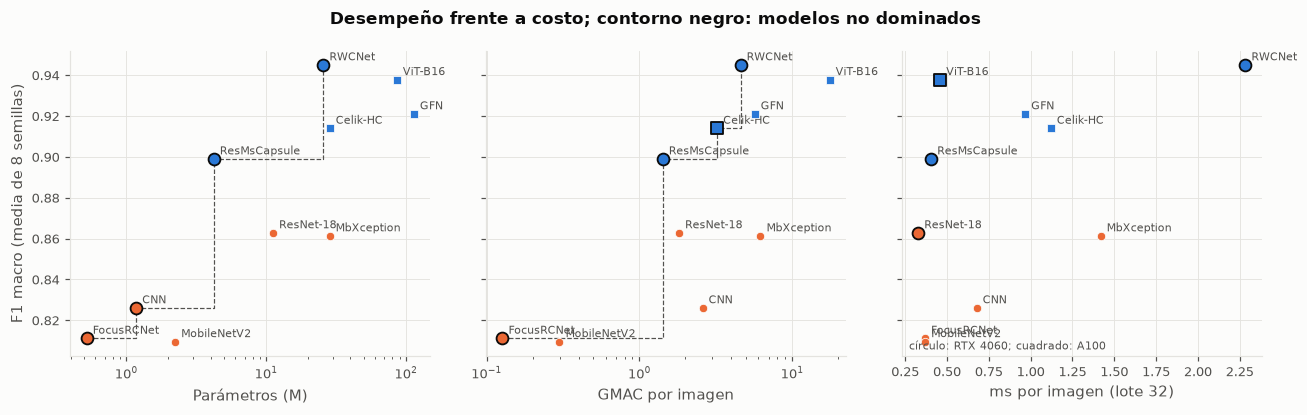

,f1,params,gmacs,ms_img,maquina,pareto_params,pareto_gmacs,pareto_latencia,eta_f1_por_gmac,eta_ic_lo,eta_ic_hi
model,,,,,,,,,,,
Celik-HC,0.9139,28424098,3.2230,1.1201,A100,False,True,False,0.0363,0.0243,0.0474
MbXception,0.8613,28393190,6.1948,1.4181,RTX 4060,False,False,False,-0.0003,-0.0039,0.0030
ViT-B16,0.9378,85803270,17.5631,0.4587,A100,False,False,True,0.0048,0.0037,0.0059
GFN,0.9210,113671336,5.6748,0.9667,A100,False,False,False,0.0151,0.0103,0.0204
FocusRCNet,0.8112,520630,0.1267,0.3680,RTX 4060,True,True,False,0.0306,0.0220,0.0398
ResMsCapsule,0.8990,4216896,1.4198,0.4048,RTX 4060,True,True,True,-0.0919,-0.1407,-0.0464
RWCNet,0.9450,25603986,4.5890,2.2830,RTX 4060,True,True,True,0.0296,0.0259,0.0332
CNN,0.8261,1174758,2.5867,0.6768,RTX 4060,True,False,False,-0.0475,-0.0644,-0.0277
MobileNetV2,0.8095,2231558,0.2995,0.3688,RTX 4060,False,False,False,0.0352,0.0233,0.0478


In [12]:
ef = pd.read_csv(COMP / "eficiencia_pareto.csv").set_index("model")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (col, lab, logx) in zip(axes, [("params", "Parámetros (M)", True), ("gmacs", "GMAC por imagen", True), ("ms_img", "ms por imagen (lote 32)", False)]):
    x = ef[col] / (1e6 if col == "params" else 1)
    pcol = {"params": "pareto_params", "gmacs": "pareto_gmacs", "ms_img": "pareto_latencia"}[col]
    for m in ef.index:
        mk = "o" if MACHINE[m] == "RTX 4060" else "s"
        ax.scatter(x[m], ef.loc[m, "f1"], s=60 if ef.loc[m, pcol] else 30, marker=mk, color=FG.color_regimen(m),
                   edgecolor=FG.INK if ef.loc[m, pcol] else FG.SURFACE, lw=1.2 if ef.loc[m, pcol] else 0.5, zorder=3)
        ax.annotate(m, (x[m], ef.loc[m, "f1"]), textcoords="offset points", xytext=(4, 3), fontsize=7, color=FG.INK2)
    if col != "ms_img":
        nd = ef[ef[pcol]].assign(x=x).sort_values("x")
        ax.step(nd.x, nd.f1, where="post", color=FG.INK2, lw=0.8, ls="--")
    if logx: ax.set_xscale("log")
    ax.set_xlabel(lab)
axes[0].set_ylabel("F1 macro (media de 8 semillas)")
axes[2].text(0.02, 0.02, "círculo: RTX 4060; cuadrado: A100", transform=axes[2].transAxes, fontsize=7.5, color=FG.INK2)
fig.suptitle("Desempeño frente a costo; contorno negro: modelos no dominados", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
display(ef[["f1", "params", "gmacs", "ms_img", "maquina", "pareto_params", "pareto_gmacs", "pareto_latencia",
            "eta_f1_por_gmac", "eta_ic_lo", "eta_ic_hi"]].round(4))

**Frontera de Pareto.** Los modelos no dominados son:

- **en parámetros:** FocusRCNet, CNN, ResMsCapsule y RWCNet;
- **en GMAC:** FocusRCNet, ResMsCapsule, Celik-HC y RWCNet.

ViT-B16 y GFN están dominados por RWCNet, que obtiene igual o mayor F1 con menos parámetros y operaciones. La latencia solo se compara dentro de cada GPU. En la RTX 4060, RWCNet es más lenta por imagen que MbXception y ResMsCapsule, pero los supera en F1. En la A100, ViT-B16 es el más rápido de los tres modelos allí entrenados.

**Costo por unidad de mejora.** El indicador es $\eta_k = (s_k - s_{\text{ResNet-18}}) / (c_k - c_{\text{ResNet-18}})$, con el costo $c$ en GMAC. Entre los modelos que superan al de referencia, Celik-HC (0.036 de F1 por GMAC adicional) y RWCNet (0.030) ofrecen la mejor relación entre mejora y costo de cómputo; GFN gana 0.015 y ViT-B16 solo 0.005, porque su costo es diez veces el de ResNet-18.

In [13]:
en = pd.read_csv(COMP / "energia_estimada.csv")
display(en.round(3))
print(f"Energía total estimada (búsqueda + 8 semillas, 10 modelos): {en.kwh_estimado.sum():.1f} kWh")

,model,maquina,tdp_W,horas_finales,horas_busqueda,kwh_estimado
0,Celik-HC,A100,400.0,0.820,0.568,0.555
1,MbXception,RTX 4060,75.0,1.356,0.709,0.155
2,ViT-B16,A100,400.0,0.462,0.358,0.328
3,GFN,A100,400.0,0.668,0.479,0.459
4,FocusRCNet,RTX 4060,75.0,1.229,0.608,0.138
5,ResMsCapsule,RTX 4060,75.0,0.711,0.660,0.103
6,RWCNet,RTX 4060,75.0,1.645,1.397,0.228
7,CNN,RTX 4060,75.0,1.117,NaN,0.084
8,MobileNetV2,RTX 4060,75.0,1.133,NaN,0.085
9,ResNet-18,RTX 4060,75.0,1.102,NaN,0.083


Energía total estimada (búsqueda + 8 semillas, 10 modelos): 2.2 kWh


**Huella energética.** La estimación multiplica la potencia nominal de la GPU (400 W la A100 SXM y 75 W la RTX 4060 Laptop) por el tiempo de entrenamiento. Es una cota superior aproximada, porque no se midió el consumo real ni se incluye la CPU. Los modelos del capítulo 4 no incluyen el tiempo de su búsqueda ni de su piloto.